# Brownian motion and Euler–Maruyama

**Brownian Motion.** A scalar *standard Brownian motion*, or *standard Wiener process*, over $[0,T]$ is a random variable $W(t)$ that depends continuously on $t \in [0,T]$ and satisfies the following three conditions.

1. $W(0) = 0$ (with probability 1).
2. For $0 \le s < t \le T$ the random variable given by the increment $W(t) - W(s)$ is normally distributed with mean zero and variance $t - s$; equivalently, $W(t) - W(s) \sim \sqrt{t-s}\,N(0,1)$, where $N(0,1)$ denotes a normally distributed random variable with zero mean and unit variance.
3. For $0 \le s < t < u < v \le T$ the increments $W(t) - W(s)$ and $W(v) - W(u)$ are independent. 

Higham (2001).

### 1. Parameters

In [132]:
import numpy as np
import matplotlib.pyplot as plt

T = 1.0
N = 1000
dt = T / N
W_0 = 0
M = 20 # nr of paths
rng = np.random.default_rng(seed=0)
t = np.linspace(0, T, N + 1)

### 2. Brownian motion in 1D

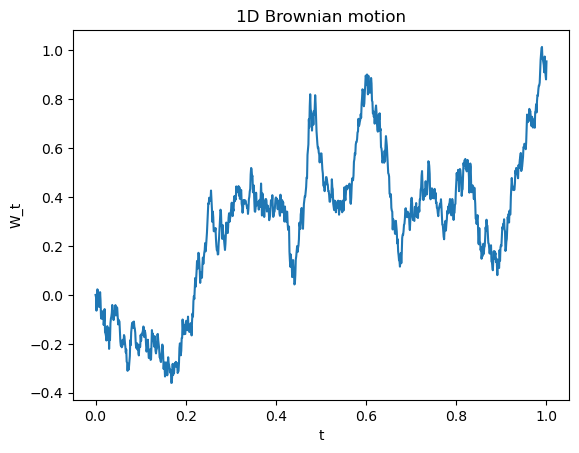

In [133]:
dW = np.zeros(len(t))
for e in range(0, len(dW)):
    dW[e] = np.random.normal(0,np.sqrt(dt))

W = np.zeros(len(t))
W[0] = 0
for i in range(1, len(t)):
    W[i] = W[i-1] + dW[i]

plt.plot(t, W)
plt.xlabel("t"); plt.ylabel("W_t"); plt.title("1D Brownian motion")
plt.show()

#### below: About 95% of the paths should be within +-2 $*\sqrt{t}$

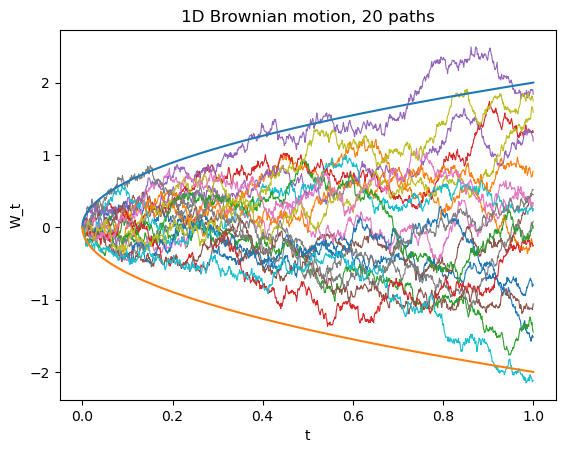

In [134]:
dW = rng.normal(0.0, np.sqrt(dt), size=(M, N))

W = np.zeros(len(t))
W = np.cumsum(dW, axis=1)
W = np.concatenate([np.zeros((M, 1)), np.cumsum(dW, axis=1)], axis=1)

plt.plot(t, W[:M].T, lw=0.8)   # first 20 paths; W[:20].T has shape (N+1, 20)
plt.plot(t, 2*np.sqrt(t))
plt.plot(t, -2*np.sqrt(t))
plt.xlabel("t"); plt.ylabel("W_t"); plt.title(f"1D Brownian motion, {M} paths")
plt.show()

### 2. Brownian Motion in higher dimensions. 
#### Below, each line represents one simulated brownian path. The euclidian norm (i.e distance) from the origin W_0 is plotted against t. The plot shows that the distance grows like $\sqrt{d*t}$. At t = T = 1 and d = 100 the paths reach a distance around 10. 

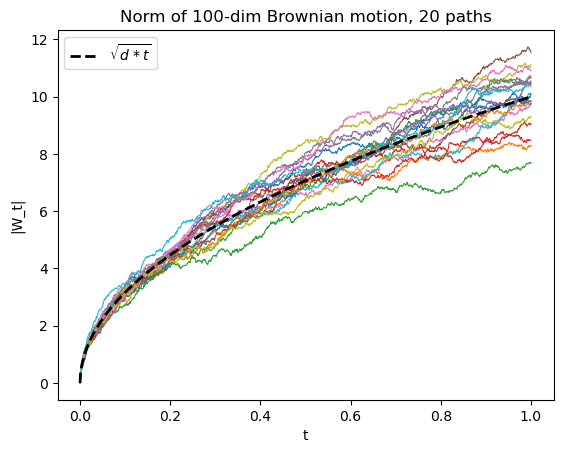

In [135]:
d = 100

dW = rng.normal(0.0, np.sqrt(dt), size=(M, N, d))

W = np.concatenate([np.zeros((M, 1, d)), np.cumsum(dW, axis=1)], axis=1)

R = np.linalg.norm(W, axis=-1)

plt.plot(t, R.T, lw=0.8)
plt.plot(t, np.sqrt(d * t), "k--", lw=2, label=r"$\sqrt{d\,*t}$")
plt.xlabel("t"); plt.ylabel("|W_t|"); plt.title(f"Norm of {d}-dim Brownian motion, {M} paths")
plt.legend()
plt.show()

### Strong convergence of Euler–Maruyama

We test the strong convergence of the Euler–Maruyama (EM) method on the linear SDE (geometric Brownian motion)

$$
dX = \lambda X\,dt + \mu X\,dW, \qquad X(0) = X_0,
$$

with $\lambda = 2$, $\mu = 1$, $X_0 = 1$ on $[0, T]$, $T = 1$. This SDE has the exact solution

$$
X(t) = X_0 \exp\!\Big( \big(\lambda - \tfrac{1}{2}\mu^2\big)t + \mu W(t) \Big),
$$

so we can measure the EM error directly.

We simulate $M = 1000$ Brownian paths on a fine grid with $\delta t = 2^{-9}$ and compute the exact $X(T)$ from $W(T)$. EM is then run with step sizes $\Delta t = R\,\delta t$, $R = 1, 2, 4, 8, 16$:

$$
X_j = X_{j-1} + \lambda X_{j-1}\,\Delta t + \mu X_{j-1}\,\Delta W_j .
$$

Each coarse increment $\Delta W_j$ is the sum of $R$ fine increments, so all step sizes use the same Brownian path, as a pathwise (strong) comparison requires.

Averaging over the paths estimates $e^{\text{strong}}_{\Delta t} = \mathbb{E}\,|X_L - X(T)|$. EM has strong order $\tfrac12$, so we expect $e \approx C\,\Delta t^{1/2}$. We estimate the order $q$ with a least-squares fit of $\log e \approx \log C + q \log \Delta t$, and expect $q \approx 0.5$. Since $e$ is a Monte Carlo estimate, the fitted $q$ varies slightly with the random seed.


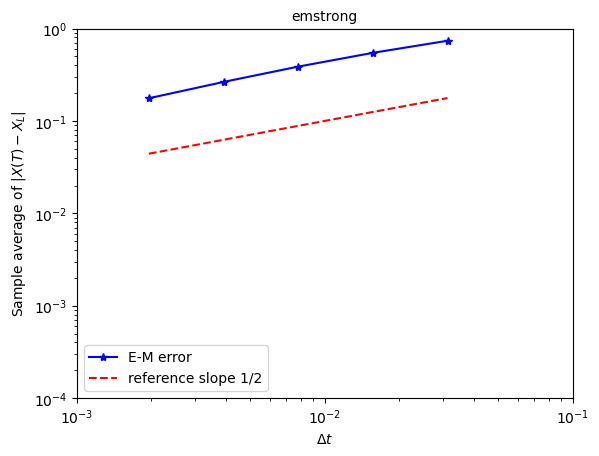

q = 0.5179, resid = 0.0671


In [ ]:
# E-M uses 5 different timesteps: 16dt, 8dt, 4dt, 2dt, dt.
# Examine strong convergence at T=1:  E | X_L - X(T) |.

rng = np.random.default_rng(100)

lam, mu, Xzero = 2.0, 1.0, 1.0
T = 1.0; N = 2**9; dt = T / N
M = 1000 # paths

Xerr = np.zeros((M, 5))
for s in range(M):
    dW = np.sqrt(dt) * rng.standard_normal(N)
    W = np.cumsum(dW) # discrete Brownian path
    Xtrue = Xzero * np.exp((lam - 0.5 * mu**2) * T + mu * W[-1])
    for p in range(5):
        R = 2**p 
        Dt = R * dt
        L = N // R # L Euler steps of size Dt = R*dt
        Xtemp = Xzero
        for j in range(L):
            Winc = np.sum(dW[R * j : R * (j + 1)]) 
            Xtemp = Xtemp + Dt * lam * Xtemp + mu * Xtemp * Winc 

        # store the error at t = 1, all five step runs sees the same brownian path
        Xerr[s, p] = abs(Xtemp - Xtrue) # store the error at t = 1,

Dtvals = dt * 2.0 ** np.arange(5)

plt.figure()
plt.loglog(Dtvals, Xerr.mean(axis=0), 'b*-', label='E-M error')
plt.loglog(Dtvals, Dtvals**0.5, 'r--', label='reference slope 1/2')
plt.axis([1e-3, 1e-1, 1e-4, 1])
plt.xlabel(r'$\Delta t$')
plt.ylabel(r'Sample average of $|X(T) - X_L|$')
plt.title('emstrong', fontsize=10)
plt.legend()
plt.show()

# Least squares fit of error = C * Dt^q
A = np.column_stack([np.ones(5), np.log(Dtvals)])
rhs = np.log(Xerr.mean(axis=0))
sol, *_ = np.linalg.lstsq(A, rhs, rcond=None)
q = sol[1]
resid = np.linalg.norm(A @ sol - rhs)
print(f"q = {q:.4f}, resid = {resid:.4f}")

### Weak convergence of Euler–Maruyama

We test the weak convergence of the Euler–Maruyama (EM) method on the same linear SDE as above,

$$
dX = \lambda X\,dt + \mu X\,dW, \qquad X(0) = X_0,
$$

with $\lambda = 2$, $\mu = 1$, $X_0 = 1$ on $[0, T]$, $T = 1$.

The weak error measures how close the averages are:

$$
e^{\text{weak}}_{\Delta t} = \big|\, \mathbb{E}[X_L] - \mathbb{E}[X(T)] \,\big|.
$$

The absolute value is taken after averaging, so errors on individual paths may cancel. 

Using $\mathbb{E}\big[e^{\mu W(T)}\big] = e^{\frac12\mu^2 T}$ (the moment generating function of $W(T) \sim N(0,T)$), the exact solution $X(T) = X_0 \exp\big((\lambda - \tfrac12\mu^2)T + \mu W(T)\big)$ gives

$$
\mathbb{E}[X(T)] = X_0\, e^{\lambda T}.
$$


As in the strong test, EM is run with $\Delta t = R\,\delta t$ for $R = 1, 2, 4, 8, 16$ and $\delta t = 2^{-9}$. For each of $M = 1000$ paths we store the endpoint $X_L$. After all paths are simulated, we estimate $\mathbb{E}[X_L]$ by the sample mean $\bar{X}_L$ and compute $|\bar{X}_L - X_0 e^{\lambda T}|$ for each step size.

EM has weak order $1$, i.e. $e^{\text{weak}}_{\Delta t} \le C\,\Delta t$. As before, we estimate the order $q$ with a least-squares fit of $\log e \approx \log C + q \log \Delta t$.

The computed error mixes two sources: Monte carlo error and EM bias.

The weak error can only be measured if the Monte Carlo error, $\text{std}(X_L)/\sqrt{M}$, is well below the EM bias. These parameters affect the MC error: 

- Number of paths $M$. More paths reduce the Monte Carlo error, but only as $1/\sqrt{M}$
- Volatility $\mu$: Lowering $\mu$ reduces $\text{std}(X_L)$ without changing $\mathbb{E}[X(T)] = X_0 e^{\lambda T}$ or the EM bias. Going from $\mu = 1$ to $\mu = 0.1$ reduces the standard deviation about ten times.

The step size does not affect the Monte Carlo error, but it sets the size of the bias, which is proportional to $\Delta t$. Very small steps make the bias so small that it is hidden by the noise. The nr of timesteps is decreased to $N = 2^8$, in order to observe the weak convergence more clearly.

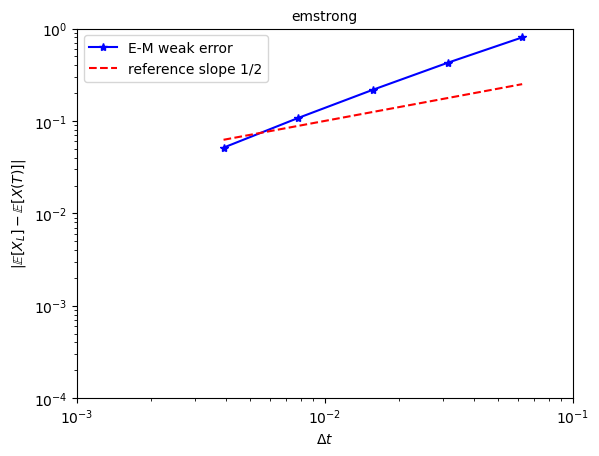

q = 0.9907, resid = 0.0650


In [149]:
# E-M uses 5 different timesteps: 16dt, 8dt, 4dt, 2dt, dt.
# Examine strong convergence at T=1:  E | X_L - X(T) |.

rng = np.random.default_rng(100)

lam, mu, Xzero = 2.0, 0.1, 1.0
T = 1.0; N = 2**8; dt = T / N
M = 10000 # paths

Xend = np.zeros((M, 5))
Ex = Xzero*np.exp(lam*T)

for s in range(M):
    dW = np.sqrt(dt) * rng.standard_normal(N)
    W = np.cumsum(dW) # discrete Brownian path
    Xtrue = Xzero * np.exp((lam - 0.5 * mu**2) * T + mu * W[-1])
    for p in range(5):
        R = 2**p 
        Dt = R * dt
        L = N // R # L Euler steps of size Dt = R*dt
        Xtemp = Xzero
        for j in range(L):
            Winc = np.sum(dW[R * j : R * (j + 1)]) 
            Xtemp = Xtemp + Dt * lam * Xtemp + mu * Xtemp * Winc 
        Xend[s, p] = Xtemp

        # store the error at t = 1, all five step runs sees the same brownian path
        #Xt at t = T
Xaverage = np.mean(Xend, axis = 0)
Xerr = np.abs(Xaverage - Ex)

Dtvals = dt * 2.0 ** np.arange(5)

plt.figure()
plt.loglog(Dtvals, Xerr, 'b*-', label='E-M weak error')
plt.loglog(Dtvals, Dtvals**0.5, 'r--', label='reference slope 1/2')
plt.axis([1e-3, 1e-1, 1e-4, 1])
plt.xlabel(r'$\Delta t$')
plt.ylabel(r'$|\mathbb{E}[X_L] - \mathbb{E}[X(T)]|$')
plt.title('emstrong', fontsize=10)
plt.legend()
plt.show()

# Least squares fit of error = C * Dt^q
A = np.column_stack([np.ones(5), np.log(Dtvals)])
rhs = np.log(Xerr)
sol, *_ = np.linalg.lstsq(A, rhs, rcond=None)
q = sol[1]
resid = np.linalg.norm(A @ sol - rhs)
print(f"q = {q:.4f}, resid = {resid:.4f}")